<a href="https://colab.research.google.com/github/disiree31-abel/cs82a-portfolio/blob/main/Module_6_Lab_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:

import pandas as pd
import sqlite3
import matplotlib.pyplot as plt

# Load the CSV files
orders = pd.read_csv("store_orders.csv")
customers = pd.read_csv("store_customers.csv")

# Create the SQLite database
con = sqlite3.connect("store.db")

# Save the DataFrames as SQL tables
orders.to_sql("orders", con, if_exists="replace", index=False)
customers.to_sql("customers", con, if_exists="replace", index=False)

# Check that both tables exist
pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", con)


,name
0,orders
1,customers


In [3]:

pd.read_sql("SELECT * FROM orders LIMIT 5", con)


,order_id,customer_id,product,category,amount,order_date
0,5000,4,paper,office,14.09,2026-05-25
1,5001,15,planner,office,51.86,2026-05-08
2,5002,34,shelf,furniture,116.25,2026-06-03
3,5003,2,granola,snacks,19.72,2026-05-19
4,5004,17,monitor,electronics,284.80,2026-05-10


In [4]:

query_over_100 = """
SELECT *
FROM orders
WHERE amount > 100
ORDER BY amount DESC
"""

over_100 = pd.read_sql(query_over_100, con)
over_100


,order_id,customer_id,product,category,amount,order_date
0,5153,20,dock,electronics,499.00,2026-05-25
1,5140,30,headset,electronics,295.36,2026-05-26
2,5047,901,headset,electronics,293.79,2026-05-15
3,5150,903,monitor,electronics,293.35,2026-06-06
4,5014,6,monitor,electronics,287.83,2026-05-22
...,...,...,...,...,...,...
79,5107,38,shelf,furniture,110.31,2026-05-17
80,5046,13,shelf,furniture,108.47,2026-05-28
81,5009,14,chair,furniture,107.20,2026-05-24
82,5007,36,dock,electronics,103.77,2026-05-21


In [5]:

query_category = """
SELECT
    category,
    COUNT(*) AS n,
    AVG(amount) AS avg_amount
FROM orders
GROUP BY category
ORDER BY avg_amount DESC
"""

category_summary = pd.read_sql(query_category, con)
category_summary


,category,n,avg_amount
0,electronics,60,190.569500
1,furniture,46,146.251522
2,office,51,30.132549
3,snacks,43,14.619767


The electronics category earns the most per order because it has the highest average order amount of $190.57.

In [6]:

query_city = """
SELECT
    c.city,
    SUM(o.amount) AS total_spend
FROM orders o
INNER JOIN customers c
    ON o.customer_id = c.customer_id
GROUP BY c.city
ORDER BY total_spend DESC
"""

city_summary = pd.read_sql(query_city, con)
city_summary


,city,total_spend
0,Los Angeles,5862.99
1,Culver City,5316.88
2,Santa Monica,4017.93
3,Inglewood,2718.25
4,Torrance,1037.25
5,Venice,462.36


In [7]:

order_count = pd.read_sql(
    "SELECT COUNT(*) AS n FROM orders", con
).iloc[0]["n"]

joined_count = pd.read_sql("""
    SELECT COUNT(*) AS n
    FROM orders o
    INNER JOIN customers c
        ON o.customer_id = c.customer_id
""", con).iloc[0]["n"]

print("Total orders:", order_count)
print("Matched orders:", joined_count)
print("Unmatched orders:", order_count - joined_count)


Total orders: 200
Matched orders: 195
Unmatched orders: 5


The orders table has more rows than the joined results because five orders have customer IDs that do not match any record in the customers table. An inner join only includes orders with matching customer records, so those five orders are excluded from the joined results.

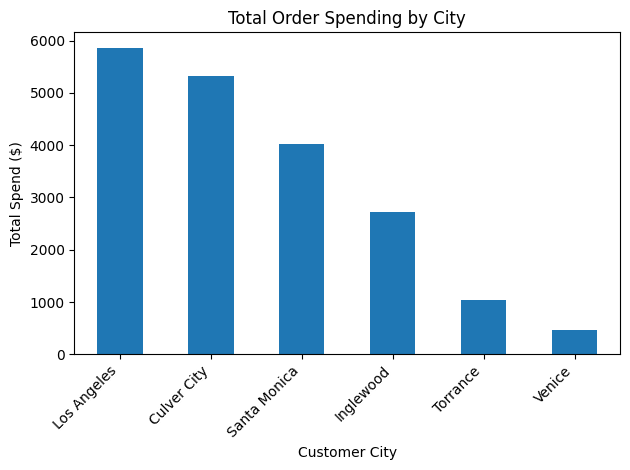

In [8]:

city_summary.plot(
    kind="bar",
    x="city",
    y="total_spend",
    legend=False
)

plt.title("Total Order Spending by City")
plt.xlabel("Customer City")
plt.ylabel("Total Spend ($)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [9]:

query_most_orders = """
SELECT
    category,
    COUNT(*) AS order_count
FROM orders
GROUP BY category
ORDER BY order_count DESC
LIMIT 1
"""

most_orders = pd.read_sql(query_most_orders, con)
most_orders


,category,order_count
0,electronics,60


The category with the most orders is electronics, with 60 orders. This helps identify which product category customers purchase most frequently.

Ethics Notes

Before sharing these results publicly, I would remove customer names and other personal information. I would also share aggregated results instead of individual customer records to protect privacy. This allows people to understand the business trends without exposing customer information.